In [1]:
import pandas as pd

In [2]:
url = "https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [6]:
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Credit_History'] = df['Credit_History'].fillna(0.0)
df[['LoanAmount', 'Credit_History']].isnull().sum()

,0
LoanAmount,0
Credit_History,0


In [7]:
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['Loan_to_Income'] = (df['LoanAmount'] * 1000) / (df['Total_Income'] * 12)
df['Risk_Flag'] = df['Loan_Status'].map({'Y': 0, 'N': 1})
df[['Loan_ID', 'Total_Income', 'Loan_to_Income', 'Risk_Flag']].head()

,Loan_ID,Total_Income,Loan_to_Income,Risk_Flag
0,LP001002,5849.0,1.823674,0
1,LP001003,6091.0,1.751218,1
2,LP001005,3000.0,1.833333,0
3,LP001006,4941.0,2.023882,0
4,LP001008,6000.0,1.958333,0


In [8]:
df.groupby('Credit_History')[['Risk_Flag', 'Loan_to_Income']].mean()

,Risk_Flag,Loan_to_Income
Credit_History,,
0.0,0.683453,2.052458
1.0,0.204211,1.971377


In [10]:
def assign_risk_tier(row):
  if row['Credit_History'] == 0.0:
    return '3. High Risk'
  elif row['Loan_to_Income'] <= 2.0:
    return '1. Low Risk'
  else:
    return '2. Moderate Risk'


df['Risk_Tier'] = df.apply(assign_risk_tier, axis=1)
df['Risk_Tier'].value_counts()

,count
Risk_Tier,
1. Low Risk,238
2. Moderate Risk,237
3. High Risk,139


In [11]:
df.groupby('Risk_Tier')[['Risk_Flag', 'Loan_to_Income', 'LoanAmount']].mean()

,Risk_Flag,Loan_to_Income,LoanAmount
Risk_Tier,,,
1. Low Risk,0.222689,1.465034,132.084034
2. Moderate Risk,0.185654,2.479855,156.337553
3. High Risk,0.683453,2.052458,151.107914


/tmp/ipykernel_1608/2201874782.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


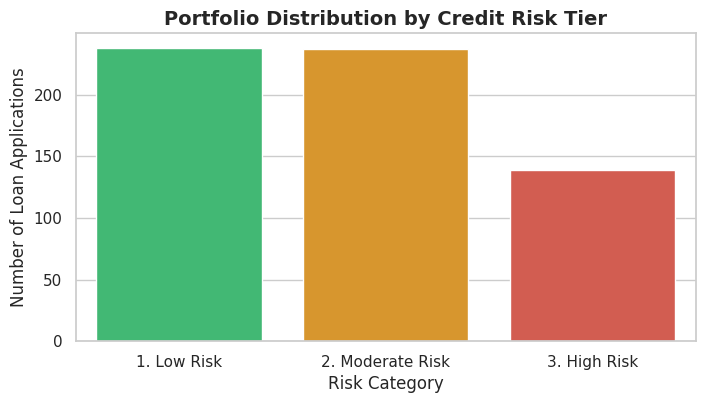

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df,
    x='Risk_Tier',
    order=['1. Low Risk', '2. Moderate Risk', '3. High Risk'],
    palette=['#2ecc71', '#f39c12', '#e74c3c'],
)
plt.title('Portfolio Distribution by Credit Risk Tier', fontsize=14, weight='bold')
plt.xlabel('Risk Category')
plt.ylabel('Number of Loan Applications')
plt.show()

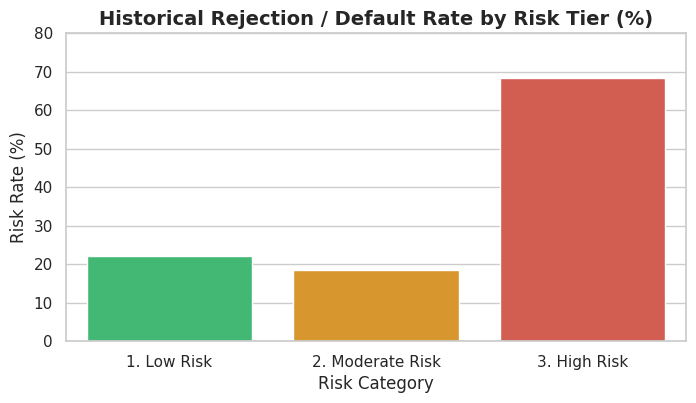

In [13]:
df['Risk_Pct'] = df['Risk_Flag'] * 100

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df,
    x='Risk_Tier',
    y='Risk_Pct',
    hue='Risk_Tier',
    order=['1. Low Risk', '2. Moderate Risk', '3. High Risk'],
    palette=['#2ecc71', '#f39c12', '#e74c3c'],
    errorbar=None,
    legend=False,
)
plt.title(
    'Historical Rejection / Default Rate by Risk Tier (%)',
    fontsize=14,
    weight='bold',
)
plt.xlabel('Risk Category')
plt.ylabel('Risk Rate (%)')
plt.ylim(0, 80)
plt.show()

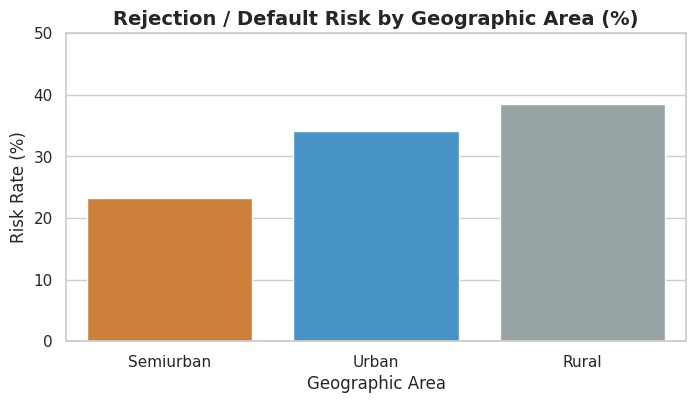

In [14]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=df,
    x='Property_Area',
    y='Risk_Pct',
    hue='Property_Area',
    order=['Semiurban', 'Urban', 'Rural'],
    palette=['#3498db', '#95a5a6', '#e67e22'],
    errorbar=None,
    legend=False,
)
plt.title(
    'Rejection / Default Risk by Geographic Area (%)', fontsize=14, weight='bold'
)
plt.xlabel('Geographic Area')
plt.ylabel('Risk Rate (%)')
plt.ylim(0, 50)
plt.show()